# <font color='#GGE15D'>**Clustering: Kmeans**</font>

## **🔸 Imports**

In [44]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.datasets import make_classification, make_blobs
from sklearn.metrics import silhouette_score, silhouette_samples
from sklearn.cluster import *

from mlxtend.plotting import plot_decision_regions

from pathlib import Path

## **🔸 Datasets**

<font color='#EE15D'> **Note: This assignment contains 4 datasets. Example 1 is the Mall Customers dataset. Examples 2, 3, and 4 are three generated datasets.**

### Example 1

In [45]:
data_path = Path("data") / "Mall_Customers.csv"

X = pd.read_csv(data_path)
X.columns = ['customer_id', 'gender', 'age', 'annual_income', 'spending_score']
X = X.drop('customer_id', axis=1)
X['gender'] = X['gender'].map({'Male': 0, 'Female': 1})
display(X.head())


X_train, X_test = train_test_split(X, test_size=0.2, random_state=0)

X_train = X_train.values
X_test = X_test.values

X_train.shape, X_test.shape

,gender,age,annual_income,spending_score
0,0,19,15,39
1,0,21,15,81
2,1,20,16,6
3,1,23,16,77
4,1,31,17,40


((160, 4), (40, 4))

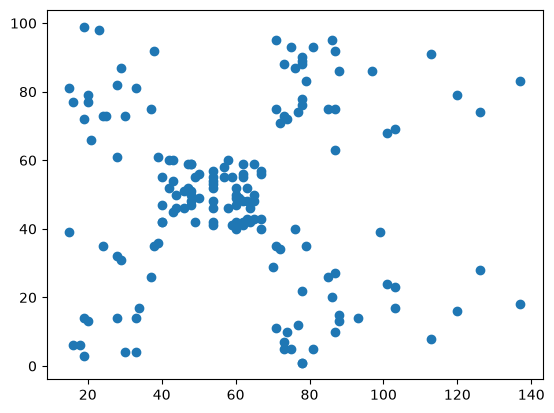

In [46]:
plt.scatter(X_train[:, -2], X_train[:, -1])

### Example 2

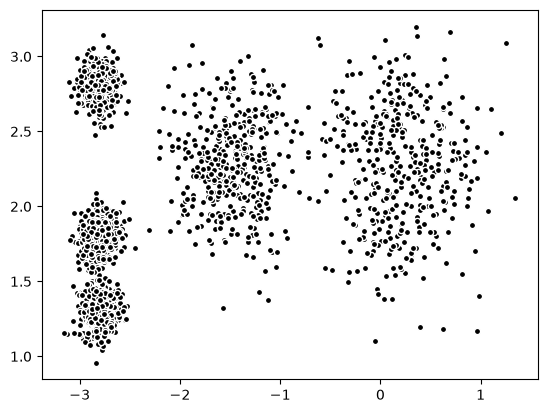

In [47]:
blob_centers = np.array([[ 0.2,  2.3],
                         [-1.5,  2.3],
                         [-2.8,  1.8],
                         [-2.8,  2.8],
                         [-2.8,  1.3]])

blob_std = np.array([0.4, 0.3, 0.1, 0.1, 0.1])

X2, y2 = make_blobs(n_samples=2000, centers=blob_centers,
                  cluster_std=blob_std, random_state=7)

plt.scatter(X2[:, 0], X2[:, 1], s=20, c='black', edgecolor='white')

### Example 3

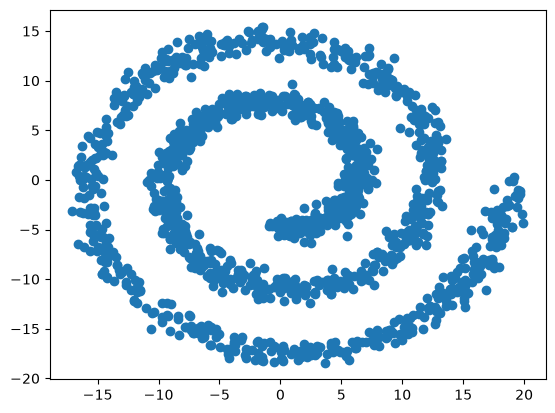

In [48]:
n_samples = 1500
np.random.seed(0)

t = 1.5 * np.pi * (1 + 3 * np.random.rand(1, n_samples))
x = t * np.cos(t)
y = t * np.sin(t)

X3 = np.concatenate((x, y))
X3 += 0.7 * np.random.randn(2, n_samples)
X3 = X3.T

plt.scatter(X3[:, 0], X3[:, 1])

### Example 4

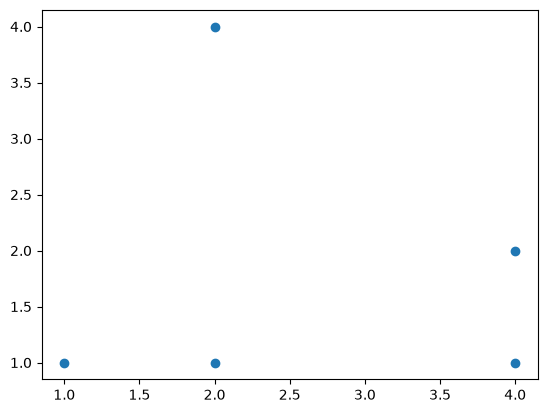

In [49]:
X4 = np.array([[1, 1], [2, 4], [2, 1], [4, 1], [4, 2]])

plt.scatter(X4[:, 0], X4[:, 1])

## **🔸 K-means**

### sklearn

In [50]:
cols = ['gender', 'age', 'annual_income', 'spending_score']
idx = [2, 3]
X = X_train[:, idx].copy()

In [51]:
X.shape

(160, 2)

<font color='#EE15D'>**Question1: Import Kmeans, Consider 3 different numbers of clusters: 2, 3, and 5 on X dataset. Finally, visualize the results and compare the plots.**

In [52]:
cluster_nums = [2, 3, 5]
models = {}

for n in cluster_nums:
    print("\nNumber of clusters, k:", n)
    models[n] = KMeans(n_clusters=n, random_state=0, n_init=10).fit(X)
    print("Dimensions of trained X:", models[n].labels_.shape)
    print("Dimensions of cluster centers:", models[n].cluster_centers_.shape)
    



Number of clusters, k: 2
Dimensions of trained X: (160,)
Dimensions of cluster centers: (2, 2)

Number of clusters, k: 3
Dimensions of trained X: (160,)
Dimensions of cluster centers: (3, 2)

Number of clusters, k: 5
Dimensions of trained X: (160,)
Dimensions of cluster centers: (5, 2)


In [53]:
x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1

xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300),
                     np.linspace(y_min, y_max, 300))
grid = np.c_[xx.ravel(), yy.ravel()]

C:\Users\MY NGOC\AppData\Local\Temp\ipykernel_21904\626639533.py:17: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()
C:\Users\MY NGOC\AppData\Local\Temp\ipykernel_21904\626639533.py:17: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()
C:\Users\MY NGOC\AppData\Local\Temp\ipykernel_21904\626639533.py:17: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()


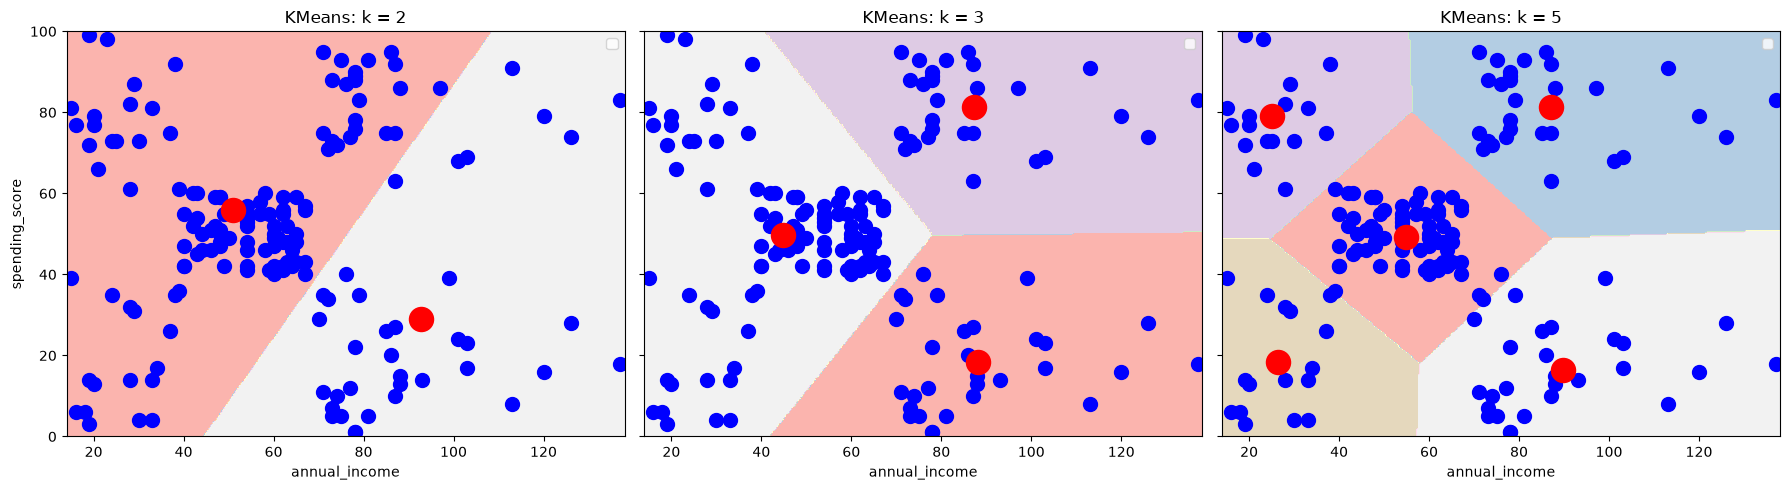

In [54]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharex=True, sharey=True)

for ax, n in zip(axes, cluster_nums):
    kmeans = models[n]
    labels = kmeans.labels_
    centroids = kmeans.cluster_centers_
    Xm = kmeans.predict(grid).reshape(xx.shape)

    ax.contourf(xx, yy, Xm, cmap=plt.cm.Pastel1)
    ax.scatter(X[:, 0], X[:, 1], s=100, c='blue')
    ax.scatter(centroids[: , 0], centroids[: , 1], s=300, c='red')

    ax.set_title(f'KMeans: k = {n}')
    ax.set_xlabel(cols[idx[0]])
    ax.set_xlim(x_min, x_max)
    ax.set_ylim(y_min, y_max)
    ax.legend()

axes[0].set_ylabel(cols[idx[1]])
fig.tight_layout()
plt.show()


**Answer for Question 1**:
For k=2, the method divides customers into 2 broad groups. Customers with substantially different income and spending patterns are group together, failing to capture the underlying structure. It shows underfitting because there are too few clusters to distinguish meaningful customer segments.

For k =3, it provides better separation, particularly between high and low spending customers with higher income. However, customers with low incomes and very different spending scores are still grouped together with the dense central group.

For k=5, it identifies 5 relatively distinct customer segments: 
- low-income/high-spending, 
- low-income/low-spending, 
- medium-income/medium spending,
- high-income/high-spending,
- and high income/low-spending.
The cluster centroids align better with the apparent structure of the dataset with more meaningful and interpretable customer segments.

However, it is not certain to establish that k=5 is statistically optimal by visual inspection. Quantitative measures such as silhouette score and elbow method should also be considered to assess cluster separation and compactness. 

## **🔸 Elbow & Silhouette**

<font color='#EE15D'> **Question2: Elbow: Write code to compute and plot the elbow curve for the X dataset. Your final plot should match the provided output. Determine where the elbow point is.**

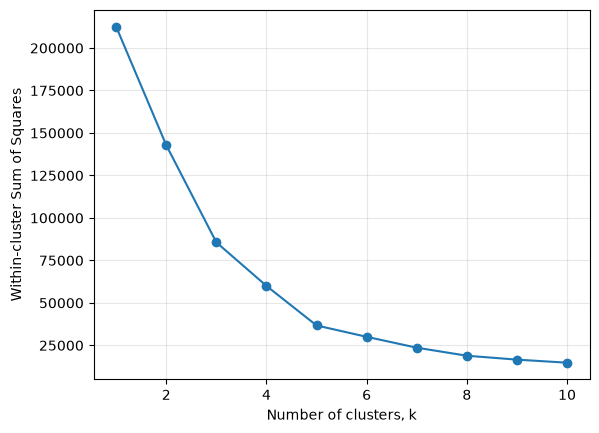

In [55]:
from matplotlib.lines import lineStyles


ks = range(1,11)
#within-cluster SS
wcss = []
models_ks = {}

for k in ks:
    models_ks[k] = KMeans(n_clusters=k, random_state=42, n_init=10)
    models_ks[k].fit(X)
    wcss.append(models_ks[k].inertia_)
    
fig,ax = plt.subplots(nrows=1, ncols=1)
ax.plot(ks, wcss, marker='o', linestyle="-")
ax.set_xlabel('Number of clusters, k')
ax.set_ylabel("Within-cluster Sum of Squares")
ax.grid(alpha=0.3)
plt.show()

**Answer for Question 2**:
The elbow point is approximately k=5, where the rate of decrease in Within-cluster Sum of Squares becomes noticeably smaller. Increasing the number of clusters, k beyond 5 provides relatively small improvement. Therefore, k=5 is a reasonable choice for optimal number of clusters, which is consistent the 5 visually distinct groups plotted in Question 1.

### Silhouette score

<font color='#EE15D'> **Question3: Calculate sillhoutte score**

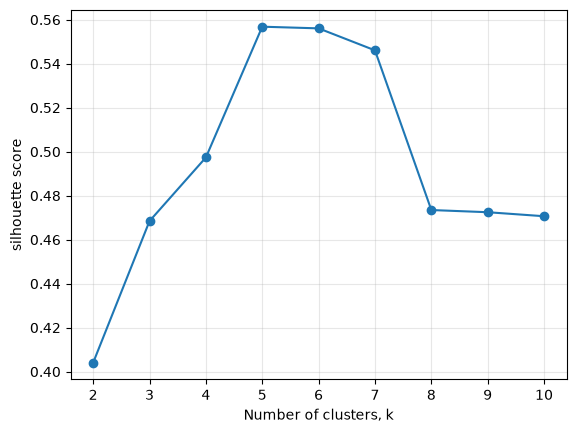

In [60]:
sillh_scores = []
ks = [k for k in ks if k>=2]

for k in ks:
    labels = models_ks[k].fit_predict(X)
    sillh_scores.append(silhouette_score(X, labels)) 
    
fig,ax = plt.subplots(nrows=1, ncols=1)
ax.plot(ks, sillh_scores, marker='o', linestyle="-")
ax.set_xlabel('Number of clusters, k')
ax.set_ylabel("silhouette score")
ax.grid(alpha=0.3)
plt.show()

## **🔸 Hierarchical Clustering**

### Example 1

<font color='#EE15D'> **Question4: Use AgglomerativeClustering of Sklearn with 5 clusters, fit on X2 data and plot it. You just need to complete agg code line**

In [ ]:
agg = ........................................................   #complete this code
agg.fit(X2)

labels = agg.labels_


plt.scatter(X2[:, 0], X2[:, 1], s=100, c=labels);

### Example 2

<font color='#EE15D'> **Question5: Apply AgglomerativeClustering on X data with 5 clusters, switch linkage between 'ward', 'single', and 'complete' and compare the plotts. Which is a better method?**

In [ ]:
cols = ['gender', 'age', 'annual_income', 'spending_score']
idx = [2, 3]
X = X_train[:, idx].copy()

In [ ]:
agg = .........................................................   #complete this code
agg.fit(X)

labels = agg.labels_

plt.scatter(X[:, 0], X[:, 1], s=100, c=labels);

### Example 3

<font color='#EE15D'> **Question6: Apply AgglomerativeClustering on X3 data with 4 clusters, and linkage = 'ward', finally visualize it**

In [ ]:
agg = ..........................................................  #complete this code
agg.fit(X3)

labels = agg.labels_


plt.scatter(X3[:, 0], X3[:, 1], s=100, c=labels);

### Dendrogram (Optional, Extra point)

For extra points, you can plot a dendrogram using Agglomerative Clustering on the X4 dataset by applying the function provided in the following link.

https://scikit-learn.org/stable/auto_examples/cluster/plot_agglomerative_dendrogram.html

In [ ]:
agg = ..............................................................  #complete this code
agg.fit(X4)

labels = agg.labels_

plt.scatter(X4[:, 0], X4[:, 1], s=100, c=labels);

In [ ]:
#Do plotting Dendogram here
#...........................................                         #complete this